# Deriving tweet analysis datasets

This notebook streams the large JSON Lines source and creates three CSV tables next to it: retweet network nodes, retweet network edges, and original tweets. It does not load the full source into memory. Run the cells from top to bottom.

In the directed network, an edge goes from the account that retweeted to the author of the retweeted tweet. Known-account edges are aggregated by account pair and include retweet count and first/last dates. If the referenced tweet is not in the source, its tweet ID is retained and target account is blank. Original tweets exclude native retweets and quote tweets; replies are retained. Counts use tweet records in the source, and hourly grouping uses UTC.

In [ ]:
from pathlib import Path
import csv, json, sqlite3, tempfile
import os
import pandas as pd
from IPython.display import display

candidates = [Path('data/msd_strike.json'), Path('msd_strike.json')]
SOURCE = next((p.resolve() for p in candidates if p.exists()), None)
if SOURCE is None:
    raise FileNotFoundError('Could not find data/msd_strike.json')
OUT_DIR = SOURCE.parent
ORIGINALS_CSV = OUT_DIR / 'original_tweets.csv'
NODES_CSV = OUT_DIR / 'retweet_network_nodes.csv'
EDGES_CSV = OUT_DIR / 'retweet_network_edges.csv'
print(f'Source: {SOURCE} ({SOURCE.stat().st_size / 1e9:.2f} GB)')
print(f'Output folder: {OUT_DIR}')
from collections import Counter, defaultdict
import matplotlib.pyplot as plt


Source: E:\courses\mining of social data\lab 1\msd_strike_tweets\msd_strike.json (4.42 GB)
Output folder: E:\courses\mining of social data\lab 1\msd_strike_tweets


## Build the three tables

The original-tweet table keeps identifiers, text, date, language, conversation/reply context, sensitivity, and engagement counts. The network tables summarize retweet ties. This same streaming pass also counts unique users, tweet types, dates, hours, and hashtags. The build can take several minutes because every source record is parsed.

In [ ]:
fd, db_name = tempfile.mkstemp(prefix='msd_retweet_index_', suffix='.sqlite')
os.close(fd)
db_path = Path(db_name)
db = sqlite3.connect(db_path)
db.execute('PRAGMA journal_mode=OFF'); db.execute('PRAGMA synchronous=OFF')
db.executescript('CREATE TABLE tweets(tweet_id TEXT PRIMARY KEY, author_id TEXT); CREATE TABLE retweets(retweet_id TEXT, source_account_id TEXT, target_tweet_id TEXT, created_at TEXT); CREATE TABLE authors(author_id TEXT PRIMARY KEY, tweet_count INTEGER);')
tweet_batch, retweet_batch, author_batch = [], [], []
records_seen = originals_written = retweets_seen = 0
quotes_seen = replies_seen = 0
type_counts = Counter()
daily_counts = defaultdict(Counter)
hour_of_day_counts = defaultdict(Counter)
hashtag_counts = Counter()
columns = ['tweet_id','author_id','created_at','text','lang','conversation_id','reply_to_tweet_id','retweet_count','reply_count','like_count','quote_count','possibly_sensitive']
with SOURCE.open('r', encoding='utf-8') as source, ORIGINALS_CSV.open('w', encoding='utf-8-sig', newline='') as out:
    writer = csv.DictWriter(out, fieldnames=columns); writer.writeheader()
    for line in source:
        if not line.strip(): continue
        tweet = json.loads(line); records_seen += 1
        tweet_id, author_id = str(tweet.get('id') or ''), str(tweet.get('author_id') or '')
        if tweet_id and author_id:
            tweet_batch.append((tweet_id, author_id)); author_batch.append((author_id,))
        refs = tweet.get('referenced_tweets') or []
        is_retweet = any(ref.get('type') == 'retweeted' for ref in refs)
        is_quote = any(ref.get('type') == 'quoted' for ref in refs)
        is_reply = any(ref.get('type') == 'replied_to' for ref in refs)
        category = 'retweets' if is_retweet else ('quotes' if is_quote else 'original_tweets')
        type_counts[category] += 1
        if is_quote: quotes_seen += 1
        if is_reply: replies_seen += 1
        created_at = tweet.get('created_at') or ''
        if len(created_at) >= 13:
            daily_counts[created_at[:10]][category] += 1
            hour_of_day_counts[created_at[11:13]][category] += 1
        for hashtag in (tweet.get('entities') or {}).get('hashtags') or []:
            tag = (hashtag.get('tag') or '').casefold()
            if tag: hashtag_counts[tag] += 1
        for ref in refs:
            if ref.get('type') == 'retweeted' and tweet_id and author_id:
                retweet_batch.append((tweet_id, author_id, str(ref.get('id') or ''), tweet.get('created_at') or '')); retweets_seen += 1
        if not any(ref.get('type') in {'retweeted','quoted'} for ref in refs):
            m = tweet.get('public_metrics') or {}
            writer.writerow({'tweet_id':tweet_id,'author_id':author_id,'created_at':tweet.get('created_at') or '', 'text':tweet.get('text') or '', 'lang':tweet.get('lang') or '', 'conversation_id':tweet.get('conversation_id') or '', 'reply_to_tweet_id':next((r.get('id','') for r in refs if r.get('type')=='replied_to'),''), 'retweet_count':m.get('retweet_count',''), 'reply_count':m.get('reply_count',''), 'like_count':m.get('like_count',''), 'quote_count':m.get('quote_count',''), 'possibly_sensitive':tweet.get('possibly_sensitive','')})
            originals_written += 1
        if len(tweet_batch) >= 10000:
            db.executemany('INSERT OR REPLACE INTO tweets VALUES (?,?)', tweet_batch)
            db.executemany('INSERT INTO authors VALUES (?,1) ON CONFLICT(author_id) DO UPDATE SET tweet_count=tweet_count+1', author_batch)
            db.executemany('INSERT INTO retweets VALUES (?,?,?,?)', retweet_batch); db.commit()
            tweet_batch.clear(); author_batch.clear(); retweet_batch.clear()
        if records_seen % 100000 == 0: print(f'Parsed {records_seen:,}; originals {originals_written:,}; retweets {retweets_seen:,}')
    if tweet_batch:
        db.executemany('INSERT OR REPLACE INTO tweets VALUES (?,?)', tweet_batch)
        db.executemany('INSERT INTO authors VALUES (?,1) ON CONFLICT(author_id) DO UPDATE SET tweet_count=tweet_count+1', author_batch)
        db.executemany('INSERT INTO retweets VALUES (?,?,?,?)', retweet_batch)
    db.commit()
db.execute('CREATE INDEX retweets_target_idx ON retweets(target_tweet_id)'); db.commit()
edge_query = '''SELECT r.source_account_id, COALESCE(t.author_id,''), CASE WHEN t.author_id IS NULL THEN r.target_tweet_id ELSE '' END, COUNT(*), COUNT(DISTINCT r.target_tweet_id), MIN(r.created_at), MAX(r.created_at) FROM retweets r LEFT JOIN tweets t ON t.tweet_id=r.target_tweet_id GROUP BY r.source_account_id,COALESCE(t.author_id,''),CASE WHEN t.author_id IS NULL THEN r.target_tweet_id ELSE '' END ORDER BY r.source_account_id,t.author_id,r.target_tweet_id'''
with EDGES_CSV.open('w', encoding='utf-8-sig', newline='') as out:
    w=csv.writer(out); w.writerow(['source_account_id','target_account_id','unresolved_target_tweet_id','retweet_count','distinct_tweets_retweeted','first_retweeted_at','last_retweeted_at']); w.writerows(db.execute(edge_query))
node_query = '''WITH endpoints AS (SELECT source_account_id account_id FROM retweets UNION SELECT t.author_id FROM retweets r JOIN tweets t ON t.tweet_id=r.target_tweet_id), sent AS (SELECT source_account_id account_id,COUNT(*) n FROM retweets GROUP BY source_account_id), received AS (SELECT t.author_id account_id,COUNT(*) n FROM retweets r JOIN tweets t ON t.tweet_id=r.target_tweet_id GROUP BY t.author_id) SELECT e.account_id,COALESCE(a.tweet_count,0),COALESCE(s.n,0),COALESCE(v.n,0) FROM endpoints e LEFT JOIN authors a ON a.author_id=e.account_id LEFT JOIN sent s ON s.account_id=e.account_id LEFT JOIN received v ON v.account_id=e.account_id ORDER BY e.account_id'''
with NODES_CSV.open('w', encoding='utf-8-sig', newline='') as out:
    w=csv.writer(out); w.writerow(['account_id','tweets_in_source','retweets_sent','retweets_received']); w.writerows(db.execute(node_query))
user_count = db.execute('SELECT COUNT(*) FROM authors').fetchone()[0]
db.close(); db_path.unlink(missing_ok=True)
print(f'Finished: {records_seen:,} records, {originals_written:,} original tweets, {retweets_seen:,} retweets, {quotes_seen:,} quote tweets, {user_count:,} unique users.')
print(f'Created {ORIGINALS_CSV.name}, {NODES_CSV.name}, and {EDGES_CSV.name}.')

Parsed 100,000; originals 13,032; retweets 84,161
Parsed 200,000; originals 26,689; retweets 167,938
Parsed 300,000; originals 40,131; retweets 251,944
Parsed 400,000; originals 50,646; retweets 339,350
Parsed 500,000; originals 60,525; retweets 427,442
Parsed 600,000; originals 69,295; retweets 516,663
Parsed 700,000; originals 77,010; retweets 607,152
Parsed 800,000; originals 83,704; retweets 698,851
Parsed 900,000; originals 91,899; retweets 788,803
Parsed 1,000,000; originals 100,858; retweets 877,831
Parsed 1,100,000; originals 109,579; retweets 966,994
Parsed 1,200,000; originals 119,559; retweets 1,054,579
Parsed 1,300,000; originals 132,735; retweets 1,138,143
Parsed 1,400,000; originals 149,473; retweets 1,215,695
Parsed 1,500,000; originals 166,706; retweets 1,294,019
Parsed 1,600,000; originals 183,529; retweets 1,373,524
Parsed 1,700,000; originals 201,413; retweets 1,451,783
Parsed 1,800,000; originals 218,359; retweets 1,530,810
Parsed 1,900,000; originals 233,596; retwe

## Dataset summary and plots

Totals use all tweet records. Hashtags are counted case-insensitively. The date plot shows counts per UTC day; the hourly plot combines records by UTC hour of day (0–23).

,measure,count
0,Unique users,827292
1,All tweet records,2170868
2,Original tweets (includes replies),266350
3,Retweets,1845108
4,Quote tweets,59410
5,Replies (subset of originals),48083
6,Hashtag occurrences,3036321
7,Distinct hashtags (case-insensitive),84999


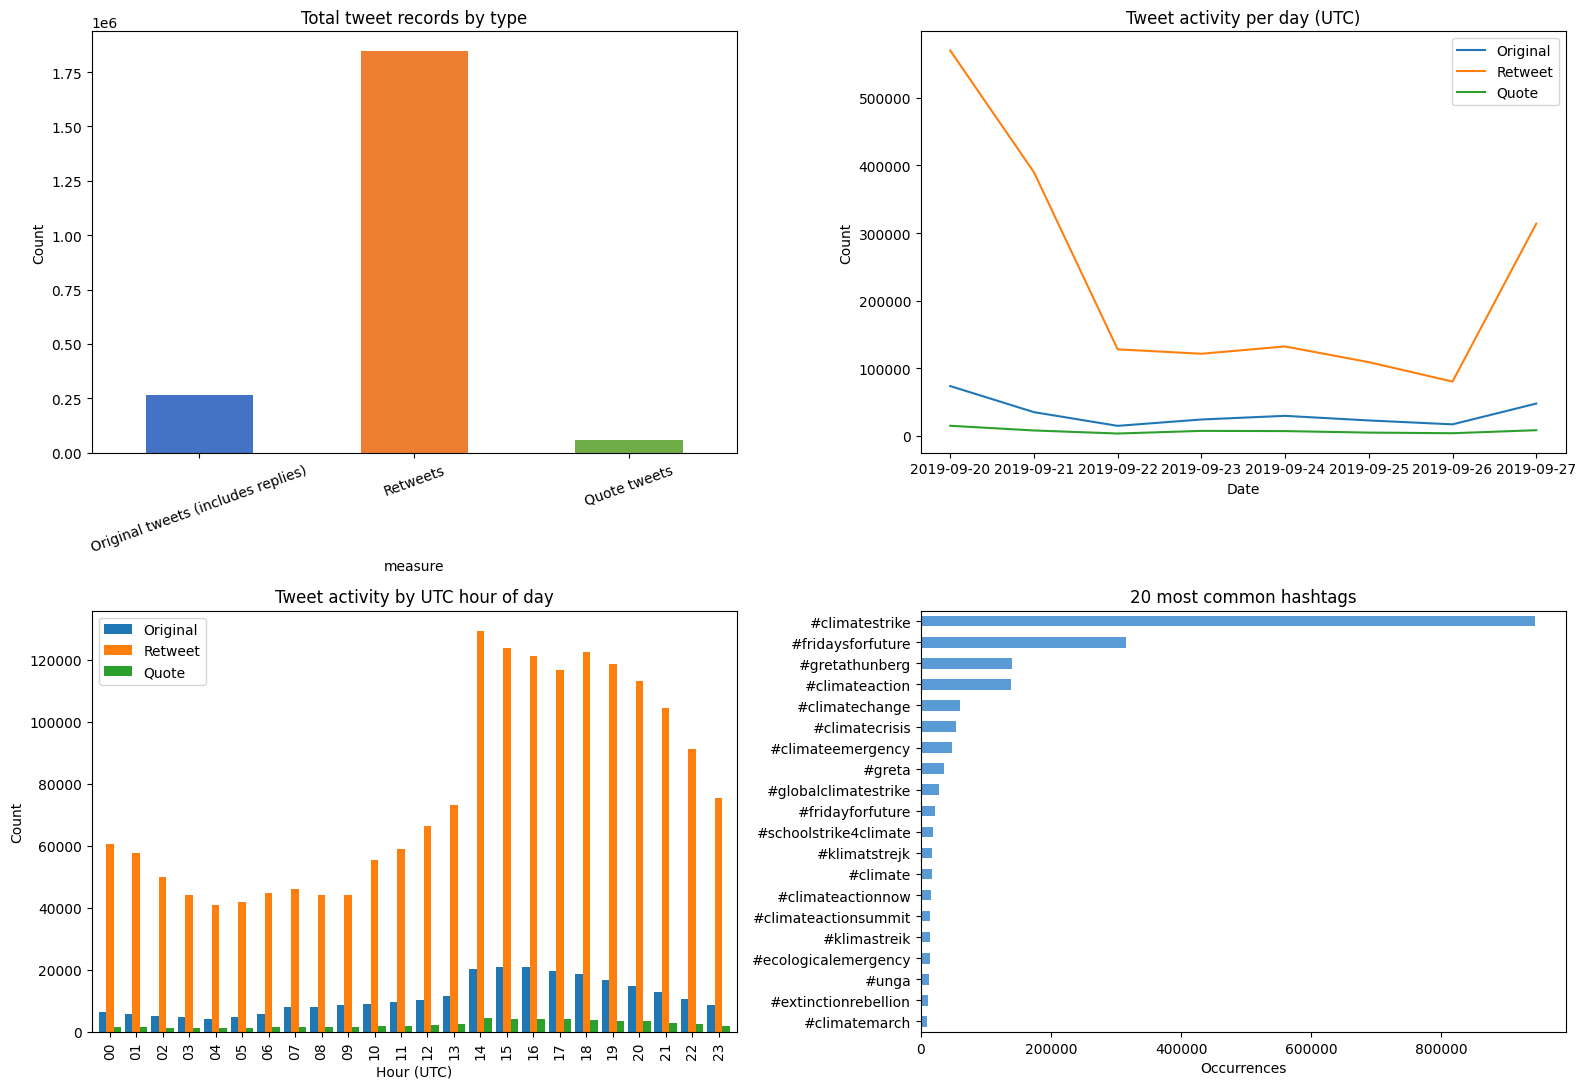

Top 20 hashtags:


,hashtag,count
0,climatestrike,943656
1,fridaysforfuture,314903
2,gretathunberg,139440
3,climateaction,138354
4,climatechange,60369
5,climatecrisis,53383
6,climateemergency,48487
7,greta,34956
8,globalclimatestrike,27551
9,fridayforfuture,21672


In [ ]:
summary = pd.DataFrame([{'measure':'Unique users','count':user_count}, {'measure':'All tweet records','count':records_seen}, {'measure':'Original tweets (includes replies)','count':type_counts['original_tweets']}, {'measure':'Retweets','count':type_counts['retweets']}, {'measure':'Quote tweets','count':type_counts['quotes']}, {'measure':'Replies (subset of originals)','count':replies_seen}, {'measure':'Hashtag occurrences','count':sum(hashtag_counts.values())}, {'measure':'Distinct hashtags (case-insensitive)','count':len(hashtag_counts)}])
display(summary)
categories = ['original_tweets','retweets','quotes']
daily_summary = pd.DataFrame.from_dict({day: dict(counts) for day,counts in daily_counts.items()}, orient='index').fillna(0).sort_index().reindex(columns=categories, fill_value=0)
hourly_summary = pd.DataFrame.from_dict({hour: dict(counts) for hour,counts in hour_of_day_counts.items()}, orient='index').fillna(0).reindex([f'{h:02d}' for h in range(24)], fill_value=0).reindex(columns=categories, fill_value=0)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
summary.iloc[2:5].set_index('measure')['count'].plot(kind='bar', ax=axes[0,0], color=['#4472C4','#ED7D31','#70AD47'])
axes[0,0].set_title('Total tweet records by type'); axes[0,0].set_ylabel('Count'); axes[0,0].tick_params(axis='x', rotation=20)
daily_summary.plot(ax=axes[0,1], linewidth=1.5); axes[0,1].set_title('Tweet activity per day (UTC)'); axes[0,1].set_xlabel('Date'); axes[0,1].set_ylabel('Count'); axes[0,1].legend(['Original','Retweet','Quote'])
hourly_summary.plot(kind='bar', ax=axes[1,0], width=0.85); axes[1,0].set_title('Tweet activity by UTC hour of day'); axes[1,0].set_xlabel('Hour (UTC)'); axes[1,0].set_ylabel('Count'); axes[1,0].legend(['Original','Retweet','Quote'])
top_hashtags = pd.Series(hashtag_counts, name='count').sort_values(ascending=False).head(20).sort_values()
top_hashtags.rename(index=lambda tag: '#' + tag).plot(kind='barh', ax=axes[1,1], color='#5B9BD5'); axes[1,1].set_title('20 most common hashtags'); axes[1,1].set_xlabel('Occurrences')
fig.tight_layout(); plt.show()
print('Top 20 hashtags:')
display(top_hashtags.sort_values(ascending=False).rename_axis('hashtag').reset_index())


## Read the derived data

The complete original-tweet table may be too large to display all at once. Use the chunk reader for full analysis; network tables are aggregated and can be loaded as DataFrames.

In [ ]:
retweet_nodes = pd.read_csv(NODES_CSV, dtype={'account_id':'string'})
retweet_edges = pd.read_csv(EDGES_CSV, dtype={'source_account_id':'string','target_account_id':'string','unresolved_target_tweet_id':'string'})
original_tweet_sample = pd.read_csv(ORIGINALS_CSV, nrows=10)
def read_original_tweet_chunks(chunksize=50000):
    return pd.read_csv(ORIGINALS_CSV, chunksize=chunksize)
print('Original tweets (first 10 rows):'); display(original_tweet_sample)
print('Retweet network edges (first 10 rows):'); display(retweet_edges.head(10))
print('Retweet network nodes (first 10 rows):'); display(retweet_nodes.head(10))
print(f'Edge rows: {len(retweet_edges):,}; node rows: {len(retweet_nodes):,}')
print('For all original tweets, iterate with: for chunk in read_original_tweet_chunks(): ...')

Original tweets (first 10 rows):


,tweet_id,author_id,created_at,text,lang,conversation_id,reply_to_tweet_id,retweet_count,reply_count,like_count,quote_count,possibly_sensitive
0,1174837416898596867,1072955978591563776,2019-09-20T00:07:22.000Z,@albertoclaveria @iresimpsonsfans #ClimateStri...,qme,1174443763596517386,1.174444e+18,0,0,0,0,False
1,1174838632496033792,3022862503,2019-09-20T00:12:12.000Z,#ClimateHoax https://t.co/g1uC27Krt2,qht,1174838632496033792,NaN,0,0,0,0,False
2,1174838703992332288,786677101365723136,2019-09-20T00:12:29.000Z,@CBSNews #Idiots \n#ClimateScam,qme,1174625057483702272,1.174625e+18,0,1,1,0,False
3,1174839596754046977,1031890039612076034,2019-09-20T00:16:01.000Z,#ClimateEmergency #ClimateConfessions I’m goin...,en,1174839596754046977,NaN,0,1,1,0,False
4,1174839932923330560,1069140295,2019-09-20T00:17:22.000Z,All this nonsense about #ClimateConfessions is...,en,1174839932923330560,NaN,0,0,1,0,False
5,1174840528778780673,1069140295,2019-09-20T00:19:44.000Z,@DrMartyFox #ClimateChangeHoax https://t.co/Nj...,qme,1174669886016118790,1.174670e+18,0,0,1,0,False
6,1174841577333755910,1069140295,2019-09-20T00:23:54.000Z,@NikolovScience @JSegor @jimdtweet @Kenneth727...,qme,1051199957976444929,1.174320e+18,0,1,0,1,False
7,1174842101982539776,1069140295,2019-09-20T00:25:59.000Z,@DrMartyFox #ClimateChangeHoax https://t.co/48...,qme,1174483178318381057,1.174483e+18,0,0,0,0,False
8,1174843444646359045,895814938995957760,2019-09-20T00:31:19.000Z,@AndreVanDelft Saluti please find the unroll h...,en,1174706185397837824,1.174843e+18,1,0,0,0,False
9,1174843716642705408,262800088,2019-09-20T00:32:24.000Z,"@charliekirk11 Apparently, #GretaThunberg's bo...",en,1174837629759541249,1.174838e+18,32,5,25,4,False


Retweet network edges (first 10 rows):


,source_account_id,target_account_id,unresolved_target_tweet_id,retweet_count,distinct_tweets_retweeted,first_retweeted_at,last_retweeted_at
0,1000000043833810945,1006419421244678144,<NA>,1,1,2019-09-26T18:34:24.000Z,2019-09-26T18:34:24.000Z
1,1000001515472474112,29417177,<NA>,1,1,2019-09-21T08:51:35.000Z,2019-09-21T08:51:35.000Z
2,1000001979060576256,<NA>,1174922605041610753,1,1,2019-09-20T20:29:51.000Z,2019-09-20T20:29:51.000Z
3,1000001979060576256,189631331,<NA>,1,1,2019-09-20T17:36:39.000Z,2019-09-20T17:36:39.000Z
4,1000001979060576256,261119379,<NA>,1,1,2019-09-20T17:36:30.000Z,2019-09-20T17:36:30.000Z
5,1000002497363283969,14159148,<NA>,1,1,2019-09-23T01:23:42.000Z,2019-09-23T01:23:42.000Z
6,1000003055717363712,1006419421244678144,<NA>,1,1,2019-09-27T11:27:42.000Z,2019-09-27T11:27:42.000Z
7,1000003055717363712,1027122188896428032,<NA>,1,1,2019-09-27T14:55:22.000Z,2019-09-27T14:55:22.000Z
8,1000003055717363712,1085976335158337536,<NA>,1,1,2019-09-27T14:48:52.000Z,2019-09-27T14:48:52.000Z
9,1000003055717363712,130881030,<NA>,1,1,2019-09-27T20:15:13.000Z,2019-09-27T20:15:13.000Z


Retweet network nodes (first 10 rows):


,account_id,tweets_in_source,retweets_sent,retweets_received
0,1000000043833810945,1,1,0
1,1000001291945500672,1,0,541
2,1000001515472474112,1,1,0
3,1000001979060576256,6,3,8
4,1000002497363283969,9,1,13
5,1000003055717363712,9,6,0
6,1000004593990979584,1,1,0
7,1000004724987518981,1,1,0
8,1000004822194585600,1,1,0
9,1000006219690541058,1,1,0


Edge rows: 1,606,902; node rows: 750,588
For all original tweets, iterate with: for chunk in read_original_tweet_chunks(): ...
